## ANNUAL AGRICULTURAL DROUGHT (CDI) 2000-2025: MAPS, RASTERS AND BASIN SERIES after comment

Skipped 3 files that do not match CDI_yyyy_mm.tif:
    CDI_duration.tif
    CDI_frequency.tif
    CDI_persistence.tif
26 years found
January average computed from 25 years
  2000: January missing, filled with the January average

Share of all pixel-months (monthly CDI):
  No drought (> -0.5)             :  41.8%
  Mild drought (-0.5 to -1.0)     :   6.8%
  Moderate drought (-1.0 to -1.5) :  10.5%
  Severe drought (-1.5 to -2)     :  14.7%
  Extreme drought (≤ -2)          :  26.3%


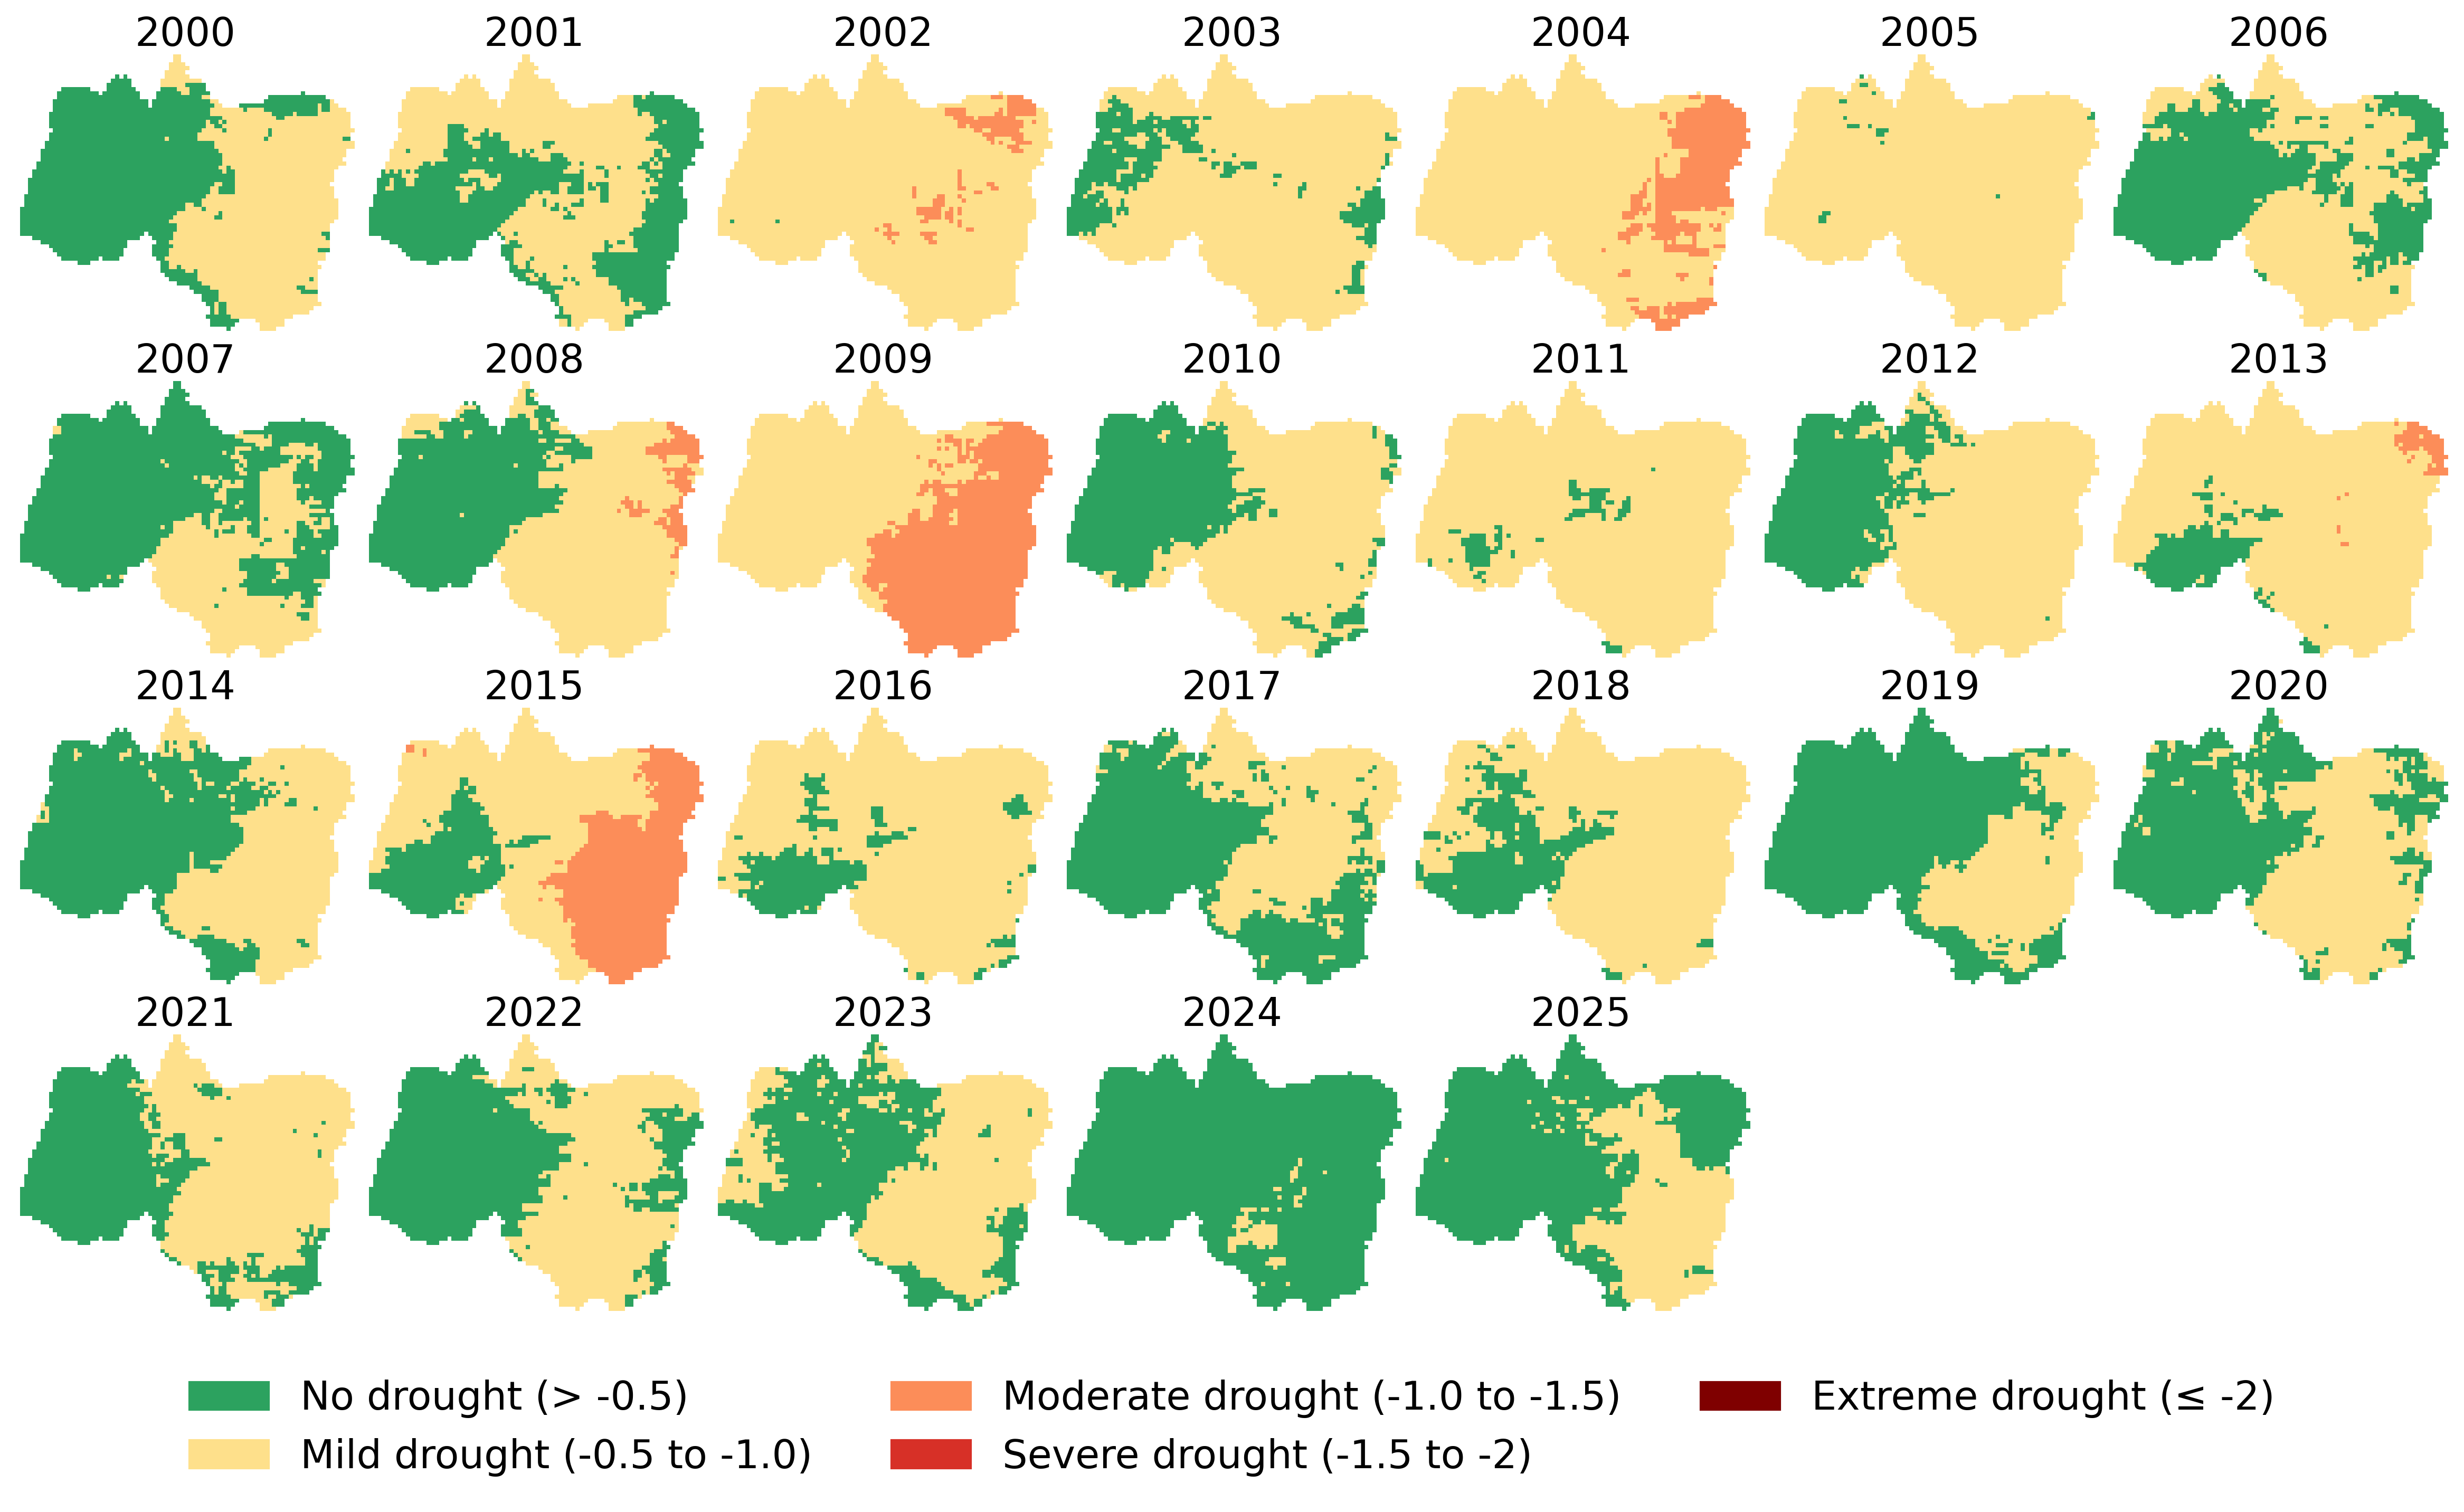


Saved figure: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_ANNUAL\CDI_26panel_5class_2000_2025.png
Saved tables: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_ANNUAL\CDI_annual_class_percent.csv and C:\Users\gerii\Documents\projects\tekeze\indices\CDI_ANNUAL\CDI_monthly_class_percent.csv
DONE


In [9]:
# =============================================================================
# ANNUAL CDI 2000-2025: DROUGHT CATEGORY MAPS (CDI-NM CLASSES)
# =============================================================================
#
# Averages the monthly CDI of each year, classifies the annual CDI with the
# CDI-NM drought categories of the reference paper, and plots one map per year.
#
# CATEGORIES:
#   0 : No drought        CDI > 0
#   1 : Mild drought      0 to -1
#   2 : Moderate drought  -1 to -1.5
#   3 : Severe drought    -1.5 to -2
#   4 : Extreme drought   <= -2
#
# MISSING MONTH:
#   January 2000 does not exist. It is replaced by the average of all available
#   Januaries (2001-2025) so that 2000 has 12 months. The filled month is used
#   only for the 2000 annual average, not in the monthly category table.
#
# INPUT:
#   indices\CDI_OUTPUT_CLIPPED\CDI_yyyy_mm.tif  (monthly CDI, range -4 to 4)
#   Files that do not match this name are skipped and listed.
#
# OUTPUT (in indices\CDI_ANNUAL):
#   CDI_26panel_5class_2000_2025.png     (the map figure)
#   CDI_annual_class_percent.csv         (share of pixels in each category, per year)
#   CDI_monthly_class_percent.csv        (share of all pixel-months in each category)
# =============================================================================

import os
import re
import csv
import glob
import warnings
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import defaultdict
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.plot import show

# =============================================================================
# SETTINGS
# =============================================================================

START_YEAR = 2000
END_YEAR   = 2025

plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9
})

# =============================================================================
# PATHS
# =============================================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices"
folder   = os.path.join(BASE_DIR, "CDI_OUTPUT_CLIPPED")
OUT_DIR  = os.path.join(BASE_DIR, "CDI_ANNUAL")
os.makedirs(OUT_DIR, exist_ok=True)

OUT_PNG   = os.path.join(OUT_DIR, "CDI_26panel_5class_2000_2025.png")
OUT_CSV_A = os.path.join(OUT_DIR, "CDI_annual_class_percent.csv")
OUT_CSV_M = os.path.join(OUT_DIR, "CDI_monthly_class_percent.csv")

files = sorted(glob.glob(os.path.join(folder, "CDI_*.tif")))

# =============================================================================
# GROUP BY YEAR (ONLY CDI_yyyy_mm.tif NAMES)
# =============================================================================

pattern = re.compile(r"^CDI_(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)
year_files = defaultdict(list)
skipped = []

for f in files:
    name = os.path.basename(f)
    mt = pattern.match(name)
    if mt is None:
        skipped.append(name)
        continue
    y, m = int(mt.group(1)), int(mt.group(2))
    if START_YEAR <= y <= END_YEAR and 1 <= m <= 12:
        year_files[y].append((m, f))

if skipped:
    print(f"Skipped {len(skipped)} files that do not match CDI_yyyy_mm.tif:")
    for s in skipped:
        print("   ", s)

for y in year_files:
    year_files[y] = sorted(year_files[y], key=lambda x: x[0])

years = sorted(year_files.keys())
print(f"{len(years)} years found")
if not years:
    raise SystemExit("No monthly CDI files found. Check the folder path and names.")

# =============================================================================
# READ HELPER
# =============================================================================

def read_cdi(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")
        if src.nodata is not None and not np.isnan(src.nodata):
            arr[arr == src.nodata] = np.nan
        return arr, src.transform

# =============================================================================
# AVERAGE JANUARY (used to fill a missing January)
# =============================================================================

jan_paths = [f for y in years for (m, f) in year_files[y] if m == 1]
jan_mean = None
if jan_paths:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        jan_mean = np.nanmean([read_cdi(p)[0] for p in jan_paths],
                              axis=0).astype("float32")
    print(f"January average computed from {len(jan_paths)} years")

# =============================================================================
# CLASSIFICATION (CDI-NM CATEGORIES)
# =============================================================================

CLASS_NAMES = {0: "No drought (> -0.5)",
               1: "Mild drought (-0.5 to -1.0)",
               2: "Moderate drought (-1.0 to -1.5)",
               3: "Severe drought (-1.5 to -2)",
               4: "Extreme drought (≤ -2)"}

def classify(a):
    cls = np.full(a.shape, np.nan)
    v = np.isfinite(a)
    cls[v & (a > -0.5)] = 0
    cls[v & (a <= -0.5) & (a > -1.0)] = 1
    cls[v & (a <= -1.0) & (a > -1.5)] = 2
    cls[v & (a <= -1.5) & (a > -2.0)] = 3
    cls[v & (a <= -2.0)] = 4
    return cls

def class_percent(cls):
    n = np.sum(~np.isnan(cls))
    if n == 0:
        return [np.nan] * 5
    return [round(float(np.sum(cls == k) / n * 100), 2) for k in range(5)]

# =============================================================================
# COLOR MAP
# =============================================================================

colors = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027", "#7f0000"]
cmap = ListedColormap(colors)
norm = BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

# =============================================================================
# FIGURE
# =============================================================================

nrows, ncols = 4, 7
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 10), dpi=300)
axes = axes.flatten()

annual_rows = []
monthly_counts = np.zeros(5)

for i, year in enumerate(years):

    stack = []
    transform = None
    months_present = set()

    for m, f in year_files[year]:
        arr, tr = read_cdi(f)
        stack.append(arr)
        months_present.add(m)
        if transform is None:
            transform = tr

        # actual months only go into the monthly category table
        mc = classify(arr)
        for k in range(5):
            monthly_counts[k] += np.sum(mc == k)

    # fill a missing January with the average of the other Januaries
    if 1 not in months_present and jan_mean is not None:
        stack.append(jan_mean)
        print(f"  {year}: January missing, filled with the January average")

    if len(stack) < 12:
        print(f"  WARNING: {year} has only {len(stack)} monthly values")

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        yearly = np.nanmean(stack, axis=0).astype("float32")

    classified = classify(yearly)
    annual_rows.append([year, len(stack), round(float(np.nanmean(yearly)), 3)]
                       + class_percent(classified))

    ax = axes[i]
    show(classified, ax=ax, cmap=cmap, norm=norm, transform=transform)

    ax.set_title(str(year), fontsize=18, pad=3)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# turn off empty panels
for j in range(len(years), len(axes)):
    axes[j].axis("off")

# =============================================================================
# SAVE TABLES (utf-8 so the "≤" sign can be written)
# =============================================================================

short_names = ["No_drought", "Mild", "Moderate", "Severe", "Extreme"]

with open(OUT_CSV_A, "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["year", "n_months", "basin_mean_CDI"] +
               [f"pct_{s}" for s in short_names])
    w.writerows(annual_rows)

tot = monthly_counts.sum()
with open(OUT_CSV_M, "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["category", "pct_of_pixel_months"])
    for k in range(5):
        w.writerow([CLASS_NAMES[k], round(float(monthly_counts[k] / tot * 100), 2)])

print("\nShare of all pixel-months (monthly CDI):")
for k in range(5):
    print(f"  {CLASS_NAMES[k]:32s}: {monthly_counts[k] / tot * 100:5.1f}%")

# =============================================================================
# LEGEND
# =============================================================================

legend_patches = [mpatches.Patch(color=colors[k], label=CLASS_NAMES[k])
                  for k in range(5)]

fig.legend(handles=legend_patches, loc="lower center", ncol=3,
           frameon=False, fontsize=18)

# =============================================================================
# CONTROL GAPS
# =============================================================================

plt.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.12,
                    wspace=0.03, hspace=0.08)

# =============================================================================
# SAVE
# =============================================================================

plt.savefig(OUT_PNG, dpi=600, bbox_inches="tight")
plt.show()

print("\nSaved figure:", OUT_PNG)
print("Saved tables:", OUT_CSV_A, "and", OUT_CSV_M)
print("DONE")

### Frenquncy and return period

In [10]:
# =============================================================================
# DROUGHT FREQUENCY AND RETURN PERIOD FROM MONTHLY CDI (2000-2025)
# =============================================================================
#
# Frequency (%)  = share of all pixel-months in the category
# Return period  = 100 / frequency (%), in months
#                  (average number of months between occurrences)
#
# TABLE 1: categories (each pixel-month falls in one category)
#   No drought        CDI > -0.5
#   Mild drought      -0.5 to -1.0
#   Moderate drought  -1.0 to -1.5
#   Severe drought    -1.5 to -2
#   Extreme drought   <= -2
#
# TABLE 2: cumulative thresholds (each includes all more severe pixels)
#   CDI <= -0.5, <= -1.0, <= -1.5, <= -2
#
# SEASON OPTION:
#   MONTHS = list(range(1, 13)) uses all months.
#   Use e.g. MONTHS = [7, 8, 9] for the rainy months only.
#
# INPUT:
#   indices\CDI_OUTPUT_CLIPPED\CDI_yyyy_mm.tif  (only real months are used)
#
# OUTPUT (in indices\CDI_ANNUAL):
#   CDI_frequency_return_period_<months>.csv
# =============================================================================

import os
import re
import csv
import glob
import numpy as np
import rasterio

START_YEAR, END_YEAR = 2000, 2025
MONTHS = list(range(1, 13))          # e.g. [7, 8, 9] for July-September

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices"
folder   = os.path.join(BASE_DIR, "CDI_OUTPUT_CLIPPED")
OUT_DIR  = os.path.join(BASE_DIR, "CDI_ANNUAL")
os.makedirs(OUT_DIR, exist_ok=True)
tag = "all_months" if MONTHS == list(range(1, 13)) else "months_" + "_".join(map(str, MONTHS))
OUT_CSV = os.path.join(OUT_DIR, f"CDI_frequency_return_period_{tag}.csv")

pattern = re.compile(r"^CDI_(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)

CATS = [
    ("No drought (> -0.5)",              lambda v: v > -0.5),
    ("Mild drought (-0.5 to -1.0)",      lambda v: (v <= -0.5) & (v > -1.0)),
    ("Moderate drought (-1.0 to -1.5)",  lambda v: (v <= -1.0) & (v > -1.5)),
    ("Severe drought (-1.5 to -2)",      lambda v: (v <= -1.5) & (v > -2.0)),
    ("Extreme drought (≤ -2)",           lambda v: v <= -2.0),
]
CUM = [
    ("Any drought (CDI ≤ -0.5)",         lambda v: v <= -0.5),
    ("Moderate or worse (≤ -1.0)",       lambda v: v <= -1.0),
    ("Severe or worse (≤ -1.5)",         lambda v: v <= -1.5),
    ("Extreme (≤ -2)",                   lambda v: v <= -2.0),
]

cnt = np.zeros(len(CATS))
cum = np.zeros(len(CUM))
total, n_files = 0, 0

for f in sorted(glob.glob(os.path.join(folder, "CDI_*.tif"))):
    mt = pattern.match(os.path.basename(f))
    if mt is None:
        continue
    y, m = int(mt.group(1)), int(mt.group(2))
    if not (START_YEAR <= y <= END_YEAR and m in MONTHS):
        continue
    with rasterio.open(f) as src:
        a = src.read(1).astype("float32")
        if src.nodata is not None and not np.isnan(src.nodata):
            a[a == src.nodata] = np.nan
    v = a[np.isfinite(a)]
    total += len(v)
    n_files += 1
    for i, (_, t) in enumerate(CATS):
        cnt[i] += np.sum(t(v))
    for i, (_, t) in enumerate(CUM):
        cum[i] += np.sum(t(v))

if total == 0:
    raise SystemExit("No CDI values found. Check the folder and MONTHS.")

def rp(freq):
    return round(100.0 / freq, 2) if freq > 0 else float("inf")

print(f"\n{n_files} monthly maps, {total:,} pixel-months, months = {MONTHS}")

rows = []
for title, items, counts in [("TABLE 1: categories", CATS, cnt),
                             ("TABLE 2: cumulative thresholds", CUM, cum)]:
    print("\n" + title)
    print(f"{'Category':36s}{'Frequency (%)':>15s}{'Return period (months)':>25s}")
    rows.append([title, "", ""])
    for (name, _), c in zip(items, counts):
        fr = round(100 * c / total, 1)
        print(f"{name:36s}{fr:15.1f}{rp(fr):25.2f}")
        rows.append([name, fr, rp(fr)])

with open(OUT_CSV, "w", newline="", encoding="utf-8-sig") as fh:
    w = csv.writer(fh)
    w.writerow(["Drought category", "Frequency (%)", "Return period (months)"])
    w.writerows(rows)

print("\nSaved:", OUT_CSV)
print("DONE")


311 monthly maps, 1,063,620 pixel-months, months = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

TABLE 1: categories
Category                              Frequency (%)   Return period (months)
No drought (> -0.5)                            41.8                     2.39
Mild drought (-0.5 to -1.0)                     6.8                    14.71
Moderate drought (-1.0 to -1.5)                10.5                     9.52
Severe drought (-1.5 to -2)                    14.7                     6.80
Extreme drought (≤ -2)                         26.3                     3.80

TABLE 2: cumulative thresholds
Category                              Frequency (%)   Return period (months)
Any drought (CDI ≤ -0.5)                       58.2                     1.72
Moderate or worse (≤ -1.0)                     51.5                     1.94
Severe or worse (≤ -1.5)                       40.9                     2.44
Extreme (≤ -2)                                 26.3                     3.80

Saved: 

### affected area under category

In [11]:
# =============================================================================
# ANNUAL CDI AFFECTED AREA (%) BY DROUGHT CATEGORY, 2000-2025
# =============================================================================
#
# Same annual maps as the 26-panel figure: mean of the 12 monthly CDI maps of
# each year (January 2000 filled with the average of the other Januaries),
# classified with the drought categories below. Gives the share of basin area
# (% of pixels) in each category for each year.
#
# CATEGORIES:
#   No drought (> -0.5) | Mild (-0.5 to -1.0) | Moderate (-1.0 to -1.5)
#   Severe (-1.5 to -2) | Extreme (<= -2)
#
# CHECK PRINTED: number of annual pixels in the "No drought" class (CDI > -0.5)
# over all years. If it is zero, every pixel of the basin was in drought in
# every year.
#
# INPUT : indices\CDI_OUTPUT_CLIPPED\CDI_yyyy_mm.tif
# OUTPUT: indices\CDI_ANNUAL\CDI_annual_area_percent.csv
#         indices\CDI_ANNUAL\CDI_annual_area_percent.png
# =============================================================================

import os
import re
import csv
import glob
import warnings
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from collections import defaultdict

START_YEAR, END_YEAR = 2000, 2025

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices"
folder   = os.path.join(BASE_DIR, "CDI_OUTPUT_CLIPPED")
OUT_DIR  = os.path.join(BASE_DIR, "CDI_ANNUAL")
os.makedirs(OUT_DIR, exist_ok=True)
OUT_CSV = os.path.join(OUT_DIR, "CDI_annual_area_percent.csv")
OUT_PNG = os.path.join(OUT_DIR, "CDI_annual_area_percent.png")

NAMES = ["No drought (> -0.5)",
         "Mild drought (-0.5 to -1.0)",
         "Moderate drought (-1.0 to -1.5)",
         "Severe drought (-1.5 to -2)",
         "Extreme drought (≤ -2)"]
SHORT  = ["No drought", "Mild", "Moderate", "Severe", "Extreme"]
COLORS = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027", "#7f0000"]

def classify(a):
    cls = np.full(a.shape, np.nan)
    v = np.isfinite(a)
    cls[v & (a > -0.5)] = 0
    cls[v & (a <= -0.5) & (a > -1.0)] = 1
    cls[v & (a <= -1.0) & (a > -1.5)] = 2
    cls[v & (a <= -1.5) & (a > -2.0)] = 3
    cls[v & (a <= -2.0)] = 4
    return cls

def read(path):
    with rasterio.open(path) as s:
        a = s.read(1).astype("float32")
        if s.nodata is not None and not np.isnan(s.nodata):
            a[a == s.nodata] = np.nan
    return a

# ---- group files by year
pattern = re.compile(r"^CDI_(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)
yf = defaultdict(dict)
for f in sorted(glob.glob(os.path.join(folder, "CDI_*.tif"))):
    mt = pattern.match(os.path.basename(f))
    if mt and START_YEAR <= int(mt.group(1)) <= END_YEAR:
        yf[int(mt.group(1))][int(mt.group(2))] = f
years = sorted(yf)
if not years:
    raise SystemExit("No monthly CDI files found.")

# ---- average January (fills a missing January)
jan = [read(yf[y][1]) for y in years if 1 in yf[y]]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    jan_mean = np.nanmean(jan, axis=0) if jan else None

rows, n_no_drought = [], 0
for y in years:
    stack = [read(p) for m, p in sorted(yf[y].items())]
    if 1 not in yf[y] and jan_mean is not None:
        stack.append(jan_mean)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        ann = np.nanmean(stack, axis=0)
    n_no_drought += int(np.sum(ann > -0.5))
    cls = classify(ann)
    n = np.sum(np.isfinite(cls))
    pct = [round(100 * float(np.sum(cls == k)) / n, 2) for k in range(5)]
    rows.append([y, round(float(np.nanmean(ann)), 3)] + pct)

# ---- table and summary
print(f"{'Year':6s}{'Mean CDI':>10s}" + "".join(f"{s:>12s}" for s in SHORT))
for r in rows:
    print(f"{r[0]:<6d}{r[1]:>10.3f}" + "".join(f"{x:>12.1f}" for x in r[2:]))

print(f"\nAnnual pixels in the no drought class (CDI > -0.5), all years: {n_no_drought}")
print("=> every pixel in drought in every year" if n_no_drought == 0
      else "=> some annual pixels are in the no drought class; do NOT state that all pixels were in drought")

arr = np.array([r[2:] for r in rows])
print("\nAverage area share over the 26 years (%):")
for k in range(5):
    print(f"  {SHORT[k]:12s}{arr[:, k].mean():6.1f}   "
          f"(min {arr[:, k].min():.1f} in {rows[arr[:, k].argmin()][0]}, "
          f"max {arr[:, k].max():.1f} in {rows[arr[:, k].argmax()][0]})")

with open(OUT_CSV, "w", newline="", encoding="utf-8-sig") as fh:
    w = csv.writer(fh)
    w.writerow(["Year", "Basin mean CDI"] + [f"{n} (%)" for n in NAMES])
    w.writerows(rows)

# ---- stacked bar figure
fig, ax = plt.subplots(figsize=(16, 6))
bottom = np.zeros(len(years))
for k in range(5):
    ax.bar([r[0] for r in rows], arr[:, k], bottom=bottom, color=COLORS[k],
           edgecolor="black", linewidth=0.4, label=NAMES[k])
    bottom += arr[:, k]
ax.set_ylabel("Basin area (%)", fontsize=18)
ax.set_xlabel("Year", fontsize=18)
ax.set_ylim(0, 100)
ax.tick_params(labelsize=14)
ax.legend(ncol=3, frameon=False, fontsize=13, loc="upper center",
          bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=400, bbox_inches="tight")
plt.close(fig)
print("\nSaved:", OUT_CSV, "and", OUT_PNG)

Year    Mean CDI  No drought        Mild    Moderate      Severe     Extreme
2000      -0.448        52.4        47.6         0.0         0.0         0.0
2001      -0.507        46.5        53.5         0.0         0.0         0.0
2002      -0.798         0.1        94.0         5.9         0.0         0.0
2003      -0.622        17.2        82.8         0.0         0.0         0.0
2004      -0.851         0.0        80.4        19.6         0.0         0.0
2005      -0.667         0.8        99.2         0.0         0.0         0.0
2006      -0.488        50.9        49.1         0.0         0.0         0.0
2007      -0.452        67.1        32.9         0.0         0.0         0.0
2008      -0.604        41.1        53.9         4.9         0.0         0.0
2009      -0.969         0.0        55.1        44.9         0.0         0.0
2010      -0.538        40.7        59.3         0.0         0.0         0.0
2011      -0.639         4.3        95.7         0.0         0.0         0.0

### averaged monthly drought category

Skipped 3 files that do not match CDI_yyyy_mm.tif:
    CDI_duration.tif
    CDI_frequency.tif
    CDI_persistence.tif

Basin-average CDI of each calendar month (26-year average):
  Jan: years = 25 | basin CDI = -2.060 | Extreme drought (≤ -2)
  Feb: years = 26 | basin CDI = -2.482 | Extreme drought (≤ -2)
  Mar: years = 26 | basin CDI = -2.331 | Extreme drought (≤ -2)
  Apr: years = 26 | basin CDI = -2.011 | Extreme drought (≤ -2)
  May: years = 26 | basin CDI = -1.332 | Moderate drought (-1 to -1.5)
  Jun: years = 26 | basin CDI = -0.048 | Mild drought (0 to -1)
  Jul: years = 26 | basin CDI =  1.654 | No drought (> 0)
  Aug: years = 26 | basin CDI =  2.244 | No drought (> 0)
  Sep: years = 26 | basin CDI =  1.599 | No drought (> 0)
  Oct: years = 26 | basin CDI =  0.230 | No drought (> 0)
  Nov: years = 26 | basin CDI = -0.854 | Mild drought (0 to -1)
  Dec: years = 26 | basin CDI = -1.563 | Severe drought (-1.5 to -2)


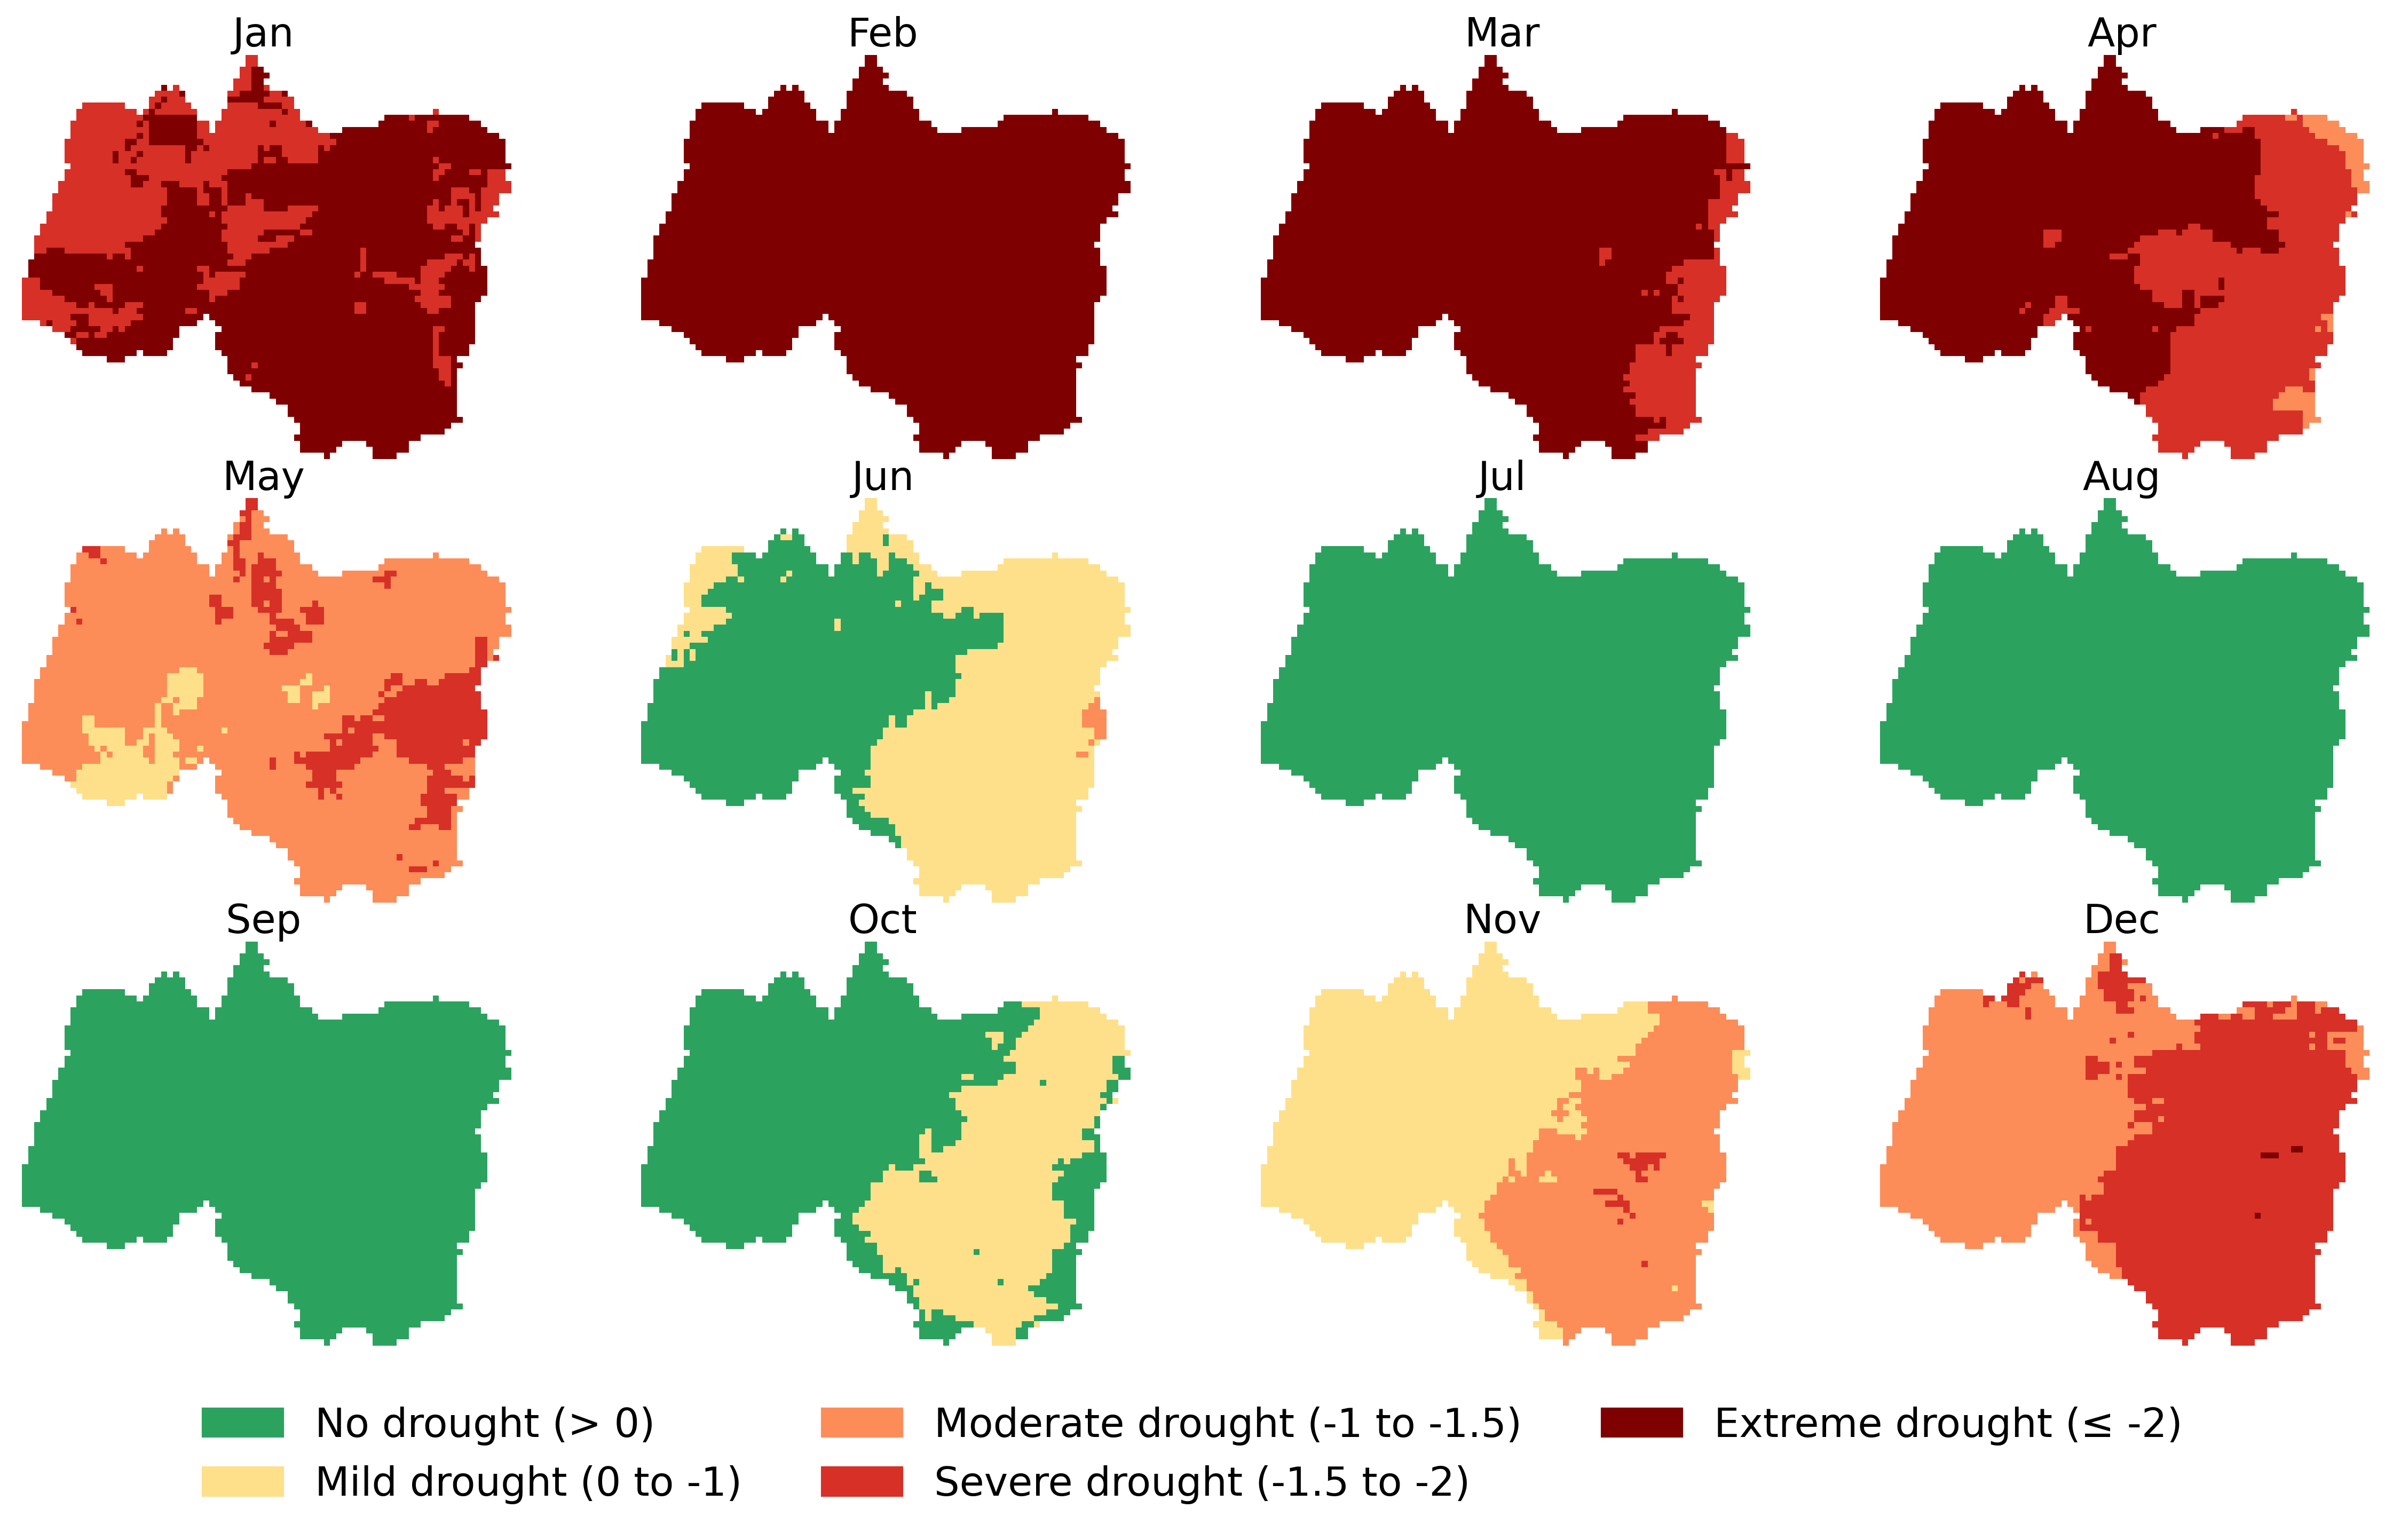


Saved figure: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_ANNUAL\CDI_monthly_mean_5class_2000_2025.png
Saved table : C:\Users\gerii\Documents\projects\tekeze\indices\CDI_ANNUAL\CDI_monthly_mean_basin_category.csv
DONE


In [5]:
# =============================================================================
# MONTHLY CDI 2000-2025: 26-YEAR AVERAGE OF EACH CALENDAR MONTH, DROUGHT CATEGORIES
# =============================================================================
#
# For each calendar month (Jan-Dec), averages the monthly CDI over 2000-2025,
# classifies the average with the CDI-NM drought categories, and plots the
# 12 months in one figure. Also gives the basin-average CDI and category of
# each month, to show drought in the rainy months.
#
# CATEGORIES:
#   0 : No drought        CDI > 0
#   1 : Mild drought      0 to -1
#   2 : Moderate drought  -1 to -1.5
#   3 : Severe drought    -1.5 to -2
#   4 : Extreme drought   <= -2
#
# JANUARY:
#   January 2000 does not exist, so the January average uses the 25 available
#   years (2001-2025). Averaging the available Januaries is the same as filling
#   January 2000 with their average, so the result is identical.
#
# INPUT:
#   indices\CDI_OUTPUT_CLIPPED\CDI_yyyy_mm.tif  (monthly CDI, range -4 to 4)
#   Files that do not match this name are skipped and listed.
#
# OUTPUT (in indices\CDI_ANNUAL):
#   CDI_monthly_mean_5class_2000_2025.png   (12-month map figure)
#   CDI_monthly_mean_basin_category.csv     (basin-average CDI, category, and
#                                            % of pixels in each category)
# =============================================================================

import os
import re
import csv
import glob
import warnings
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import defaultdict
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.plot import show

# =============================================================================
# SETTINGS
# =============================================================================

START_YEAR = 2000
END_YEAR   = 2025

MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9
})

# =============================================================================
# PATHS
# =============================================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices"
folder   = os.path.join(BASE_DIR, "CDI_OUTPUT_CLIPPED")
OUT_DIR  = os.path.join(BASE_DIR, "CDI_ANNUAL")
os.makedirs(OUT_DIR, exist_ok=True)

OUT_PNG = os.path.join(OUT_DIR, "CDI_monthly_mean_5class_2000_2025.png")
OUT_CSV = os.path.join(OUT_DIR, "CDI_monthly_mean_basin_category.csv")

# =============================================================================
# GROUP FILES BY CALENDAR MONTH
# =============================================================================

pattern = re.compile(r"^CDI_(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)
month_files = defaultdict(list)
skipped = []

for f in sorted(glob.glob(os.path.join(folder, "CDI_*.tif"))):
    name = os.path.basename(f)
    mt = pattern.match(name)
    if mt is None:
        skipped.append(name)
        continue
    y, m = int(mt.group(1)), int(mt.group(2))
    if START_YEAR <= y <= END_YEAR and 1 <= m <= 12:
        month_files[m].append(f)

if skipped:
    print(f"Skipped {len(skipped)} files that do not match CDI_yyyy_mm.tif:")
    for s in skipped:
        print("   ", s)

if not month_files:
    raise SystemExit("No monthly CDI files found. Check the folder path and names.")

# =============================================================================
# CLASSIFICATION (CDI-NM CATEGORIES)
# =============================================================================

CLASS_NAMES = {0: "No drought (> 0)",
               1: "Mild drought (0 to -1)",
               2: "Moderate drought (-1 to -1.5)",
               3: "Severe drought (-1.5 to -2)",
               4: "Extreme drought (≤ -2)"}

def classify(arr):
    cls = np.full(arr.shape, np.nan)
    valid = ~np.isnan(arr)
    cls[valid & (arr > 0)] = 0
    cls[valid & (arr <= 0)    & (arr > -1.0)] = 1   # Mild: 0 to -1
    cls[valid & (arr <= -1.0) & (arr > -1.5)] = 2
    cls[valid & (arr <= -1.5) & (arr > -2.0)] = 3
    cls[valid & (arr <= -2.0)] = 4
    return cls

def class_percent(cls):
    n = np.sum(~np.isnan(cls))
    if n == 0:
        return [np.nan] * 5
    return [round(float(np.sum(cls == k) / n * 100), 2) for k in range(5)]

# =============================================================================
# COLOR MAP (same as the annual figure)
# =============================================================================

colors = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027", "#7f0000"]
cmap = ListedColormap(colors)
norm = BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

# =============================================================================
# FIGURE: 3 rows x 4 columns (Jan-Dec)
# =============================================================================

fig, axes = plt.subplots(3, 4, figsize=(16, 10), dpi=300)
axes = axes.flatten()

rows = []
print("\nBasin-average CDI of each calendar month (26-year average):")

for m in range(1, 13):

    ax = axes[m - 1]
    stack, transform = [], None

    for f in month_files.get(m, []):
        with rasterio.open(f) as src:
            arr = src.read(1).astype("float32")
            if src.nodata is not None and not np.isnan(src.nodata):
                arr[arr == src.nodata] = np.nan
            stack.append(arr)
            if transform is None:
                transform = src.transform

    if not stack:
        ax.axis("off")
        continue

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean_map = np.nanmean(stack, axis=0).astype("float32")

    classified = classify(mean_map)
    basin_cdi  = float(np.nanmean(mean_map))
    basin_cls  = int(classify(np.array([basin_cdi]))[0])

    rows.append([MONTH_NAMES[m - 1], len(stack), round(basin_cdi, 3),
                 CLASS_NAMES[basin_cls]] + class_percent(classified))
    print(f"  {MONTH_NAMES[m - 1]}: years = {len(stack):2d} | "
          f"basin CDI = {basin_cdi:6.3f} | {CLASS_NAMES[basin_cls]}")

    show(classified, ax=ax, cmap=cmap, norm=norm, transform=transform)

    ax.set_title(MONTH_NAMES[m - 1], fontsize=18, pad=3)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# =============================================================================
# SAVE TABLE (utf-8 so the "≤" sign can be written)
# =============================================================================

short_names = ["No_drought", "Mild", "Moderate", "Severe", "Extreme"]

with open(OUT_CSV, "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["month", "n_years", "basin_mean_CDI", "basin_category"] +
               [f"pct_{s}" for s in short_names])
    w.writerows(rows)

# =============================================================================
# LEGEND
# =============================================================================

legend_patches = [mpatches.Patch(color=colors[k], label=CLASS_NAMES[k])
                  for k in range(5)]

fig.legend(handles=legend_patches, loc="lower center", ncol=3,
           frameon=False, fontsize=18)

# =============================================================================
# CONTROL GAPS
# =============================================================================

plt.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.12,
                    wspace=0.03, hspace=0.08)

# =============================================================================
# SAVE
# =============================================================================

plt.savefig(OUT_PNG, dpi=600, bbox_inches="tight")
plt.show()

print("\nSaved figure:", OUT_PNG)
print("Saved table :", OUT_CSV)
print("DONE")

### ANNUAL AGRICULTURAL CD) 2000-2025: no threshold/category

26 annual rasters found
Colour scale: -1.14 to 1.14


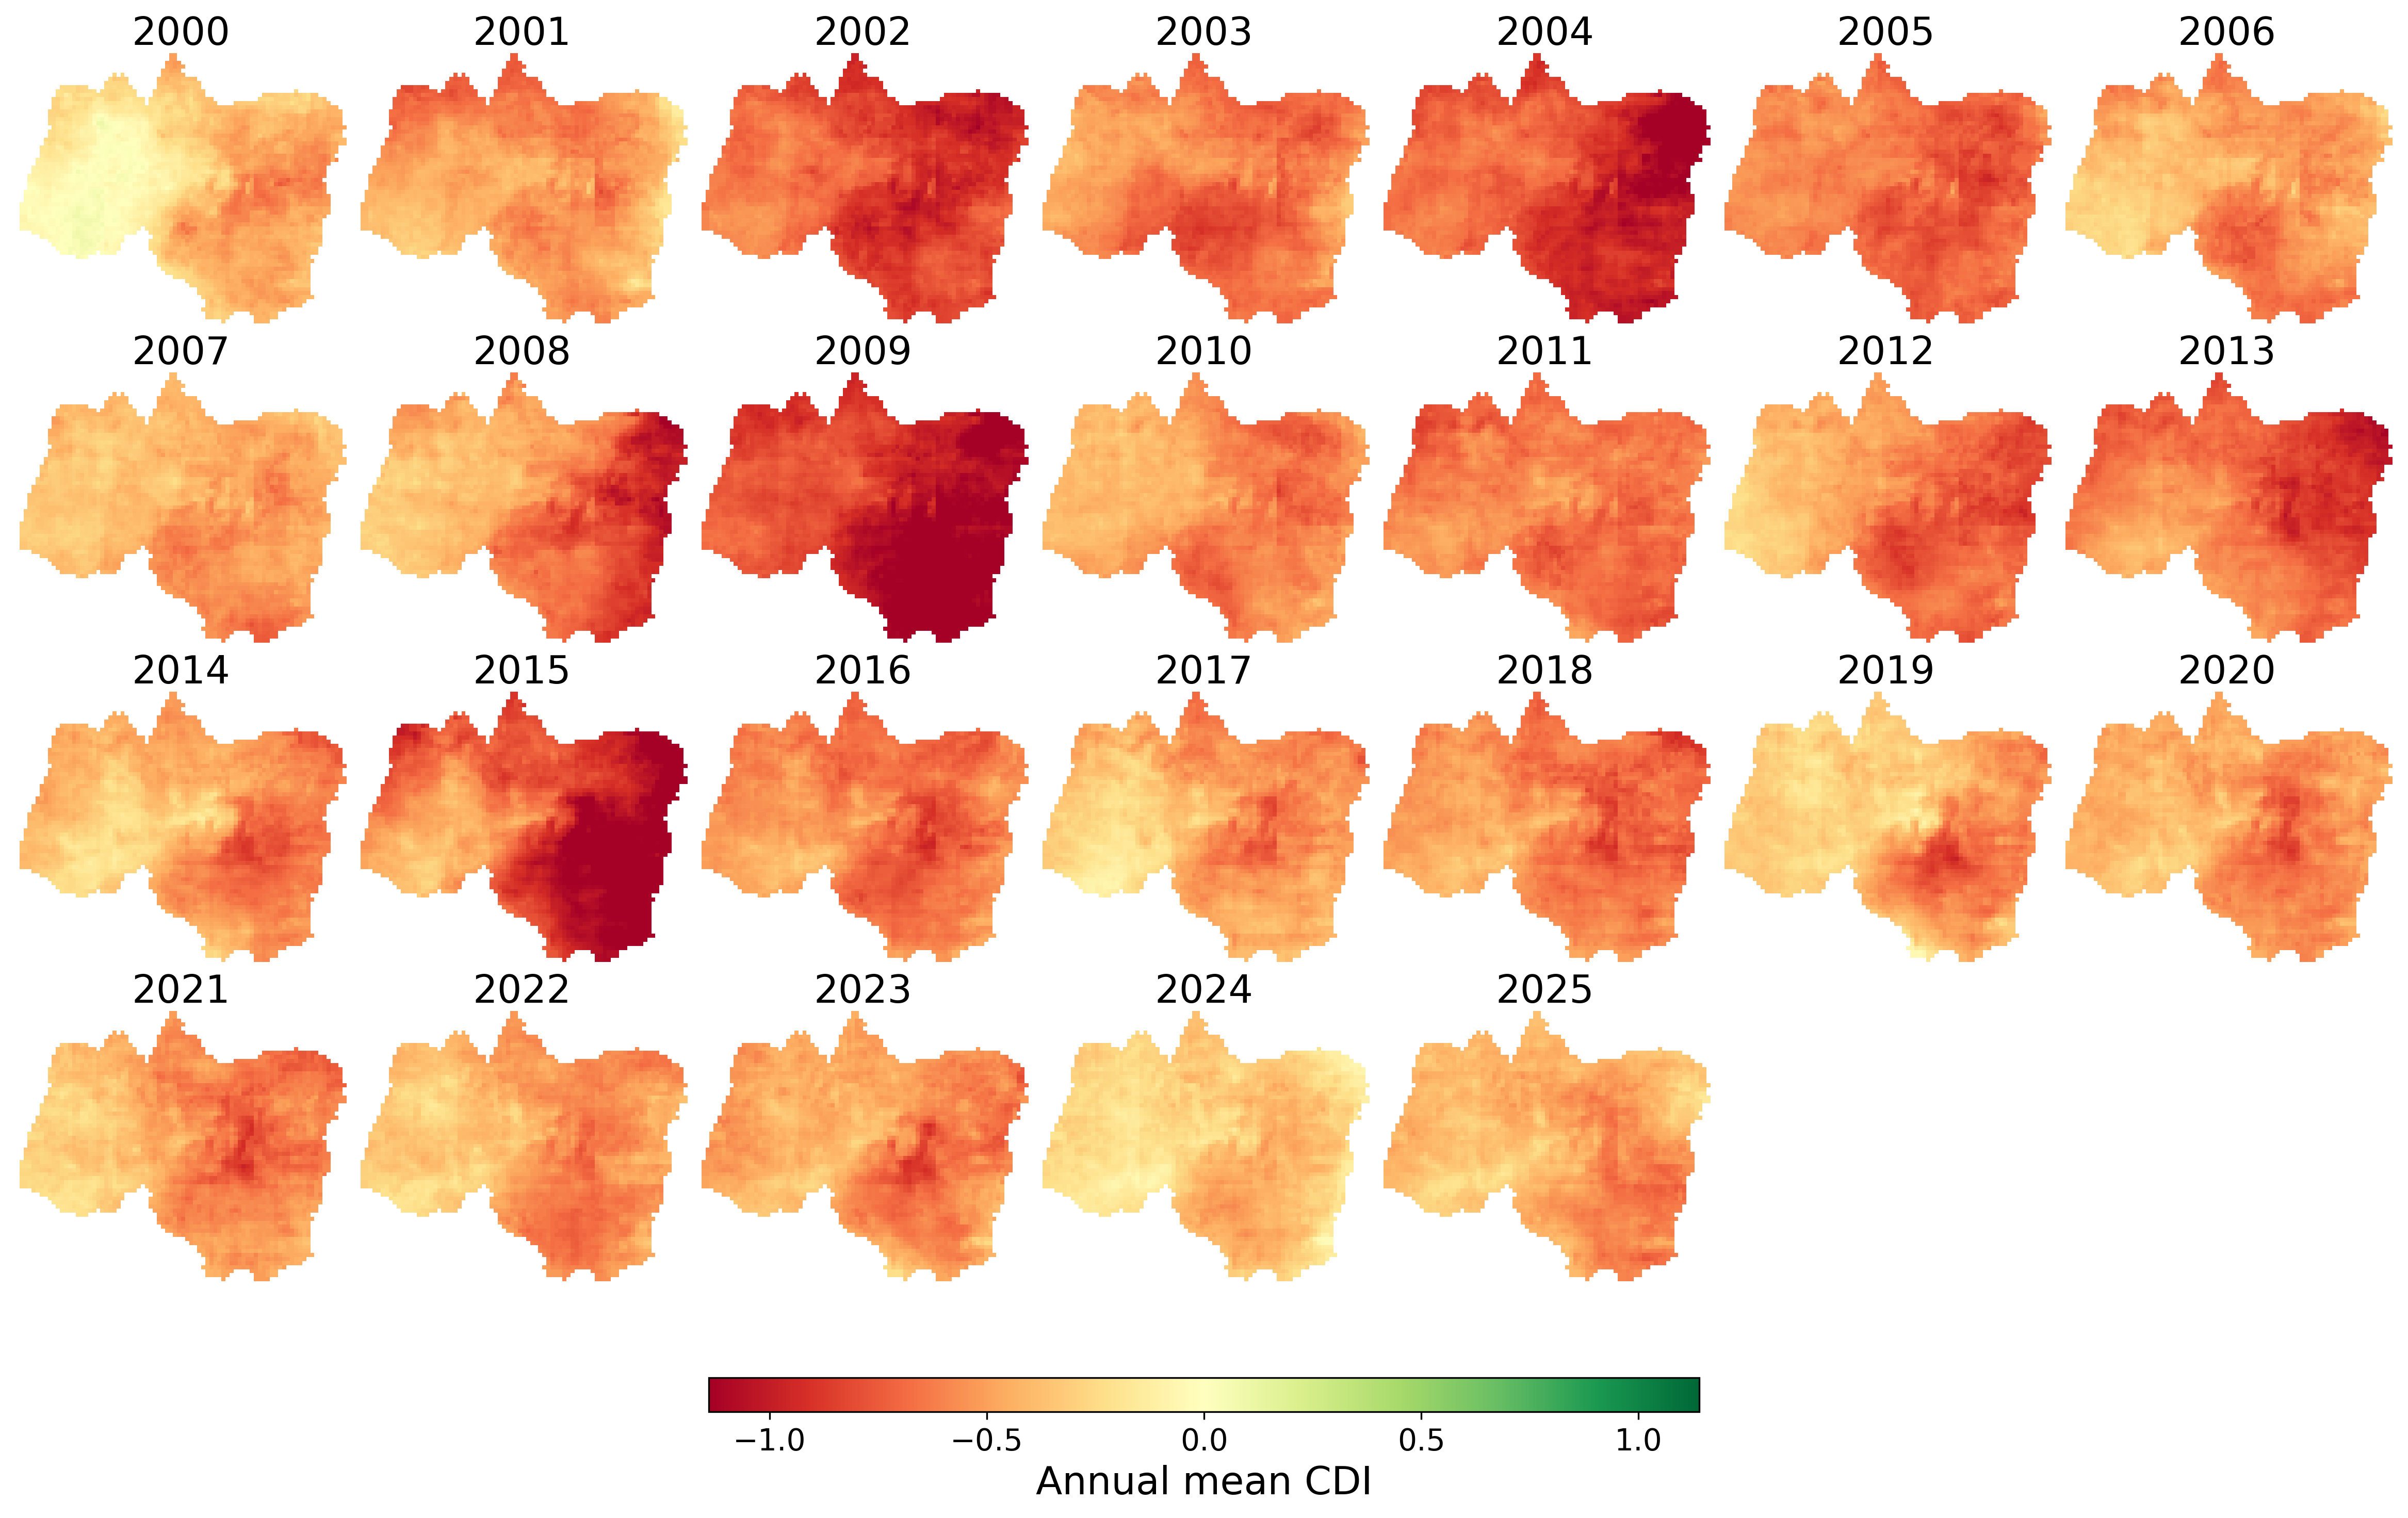

Saved: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_ANNUAL\CDI_annual_continuous_2000_2025.png


In [4]:
# =============================================================================
# MAP ANNUAL CDI RASTERS (2000-2025) FROM CDI_ANNUAL, CONTINUOUS VALUES
# =============================================================================
#
# Reads the existing annual CDI GeoTIFFs and plots one map per year, with one
# shared colour scale and colour bar. No averaging, no drought classes.
#
# INPUT:
#   indices\CDI_ANNUAL\CDI_annual_yyyy.tif
#
# OUTPUT:
#   indices\CDI_ANNUAL\CDI_annual_continuous_2000_2025.png
# =============================================================================

import os
import re
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from rasterio.plot import show

# =============================================================================
# SETTINGS
# =============================================================================

START_YEAR  = 2000
END_YEAR    = 2025
CMAP_NAME   = "RdYlGn"     # red = dry, green = wet
FIXED_LIMIT = None         # None = automatic symmetric limits; or e.g. 2.0

folder  = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_ANNUAL"
OUT_PNG = os.path.join(folder, "CDI_annual_continuous_2000_2025.png")

# =============================================================================
# FIND THE ANNUAL FILES
# =============================================================================

pattern = re.compile(r"^CDI_annual_(\d{4})\.tif$", re.IGNORECASE)
year_file = {}

for f in glob.glob(os.path.join(folder, "*.tif")):
    m = pattern.match(os.path.basename(f))
    if m and START_YEAR <= int(m.group(1)) <= END_YEAR:
        year_file[int(m.group(1))] = f

years = sorted(year_file)
print(f"{len(years)} annual rasters found")
if not years:
    raise SystemExit("No CDI_annual_yyyy.tif files found. Check the folder.")

# =============================================================================
# READ THE RASTERS
# =============================================================================

arrays, transforms = {}, {}
for y in years:
    with rasterio.open(year_file[y]) as src:
        a = src.read(1).astype("float32")
        if src.nodata is not None and not np.isnan(src.nodata):
            a[a == src.nodata] = np.nan
        arrays[y] = a
        transforms[y] = src.transform

# =============================================================================
# SHARED COLOUR LIMITS (SYMMETRIC AROUND 0)
# =============================================================================

if FIXED_LIMIT is not None:
    lim = float(FIXED_LIMIT)
else:
    vals = np.concatenate([a[~np.isnan(a)] for a in arrays.values()])
    lim = float(max(abs(np.percentile(vals, 2)), abs(np.percentile(vals, 98))))

norm = Normalize(vmin=-lim, vmax=lim)
print(f"Colour scale: {-lim:.2f} to {lim:.2f}")

# =============================================================================
# FIGURE
# =============================================================================

nrows, ncols = 4, 7
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 10), dpi=300)
axes = axes.flatten()

for i, y in enumerate(years):
    ax = axes[i]
    show(arrays[y], ax=ax, cmap=CMAP_NAME, norm=norm, transform=transforms[y])
    ax.set_title(str(y), fontsize=18, pad=3)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

for j in range(len(years), len(axes)):
    axes[j].axis("off")

sm = ScalarMappable(norm=norm, cmap=CMAP_NAME)
sm.set_array([])
cax = fig.add_axes([0.30, 0.045, 0.40, 0.022])
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.set_label("Annual mean CDI", fontsize=18)
cbar.ax.tick_params(labelsize=14)

plt.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.12,
                    wspace=0.03, hspace=0.08)

plt.savefig(OUT_PNG, dpi=600, bbox_inches="tight")
plt.show()
print("Saved:", OUT_PNG)

### monthly AGRICULTURAL CDI 2000-2025: no threshold/category

In [6]:
# =============================================================================
# MONTHLY CDI 2000-2025: SINGLE PNG, 26 ROWS (YEARS) x 12 COLUMNS (MONTHS)
# =============================================================================
#
# Reads the monthly CDI GeoTIFFs and plots all months of all years in ONE
# figure: each row is a year, each column a month (Jan-Dec).
# One shared continuous colour scale and one colour bar. No drought classes.
#
# INPUT:
#   indices\CDI_OUTPUT_CLIPPED\CDI_yyyy_mm.tif
#   Files that do not match this name pattern are skipped and listed.
#
# OUTPUT:
#   indices\CDI_MONTHLY_MAPS\CDI_monthly_26x12_2000_2025.png
# =============================================================================

import os
import re
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# =============================================================================
# SETTINGS
# =============================================================================

START_YEAR  = 2000
END_YEAR    = 2025

CMAP_NAME   = "RdYlGn"      # red = dry, green = wet
FIXED_LIMIT = None          # None = automatic symmetric limits; or e.g. 2.0
DPI         = 250           # 250 gives about 4500 x 10000 px; lower if memory is tight

MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

FS_MONTH = 20               # month names on the top row
FS_YEAR  = 20               # year labels on the left column
FS_CBAR  = 24               # colour bar label and ticks

# =============================================================================
# PATHS
# =============================================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices"
folder   = os.path.join(BASE_DIR, "CDI_OUTPUT_CLIPPED")
OUT_DIR  = os.path.join(BASE_DIR, "CDI_MONTHLY_MAPS")
os.makedirs(OUT_DIR, exist_ok=True)
OUT_PNG  = os.path.join(OUT_DIR, "CDI_monthly_26x12_2000_2025.png")

# =============================================================================
# FIND THE MONTHLY FILES
# =============================================================================

pattern = re.compile(r"^CDI_(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)
files = {}                      # (year, month) -> path
skipped = []

for f in sorted(glob.glob(os.path.join(folder, "CDI_*.tif"))):
    name = os.path.basename(f)
    mt = pattern.match(name)
    if mt is None:
        skipped.append(name)
        continue
    y, m = int(mt.group(1)), int(mt.group(2))
    if START_YEAR <= y <= END_YEAR and 1 <= m <= 12:
        files[(y, m)] = f

if skipped:
    print(f"Skipped {len(skipped)} files that do not match CDI_yyyy_mm.tif:")
    for s in skipped:
        print("   ", s)

years = list(range(START_YEAR, END_YEAR + 1))
print(f"{len(files)} monthly files found (expected {len(years) * 12})")
if not files:
    raise SystemExit("No monthly CDI files found. Check the folder path and names.")

# =============================================================================
# READ ALL RASTERS ONCE (kept in memory as float32)
# =============================================================================

arrays = {}
extent = None

for (y, m), f in files.items():
    with rasterio.open(f) as src:
        a = src.read(1).astype("float32")
        if src.nodata is not None and not np.isnan(src.nodata):
            a[a == src.nodata] = np.nan
        arrays[(y, m)] = a
        if extent is None:
            b = src.bounds
            extent = (b.left, b.right, b.bottom, b.top)

# =============================================================================
# SHARED COLOUR LIMITS (SYMMETRIC AROUND 0)
# =============================================================================

if FIXED_LIMIT is not None:
    lim = float(FIXED_LIMIT)
else:
    rng = np.random.default_rng(42)
    sample = []
    for a in arrays.values():
        v = a[~np.isnan(a)]
        if len(v) > 2000:
            v = rng.choice(v, 2000, replace=False)
        sample.append(v)
    sample = np.concatenate(sample)
    lim = float(max(abs(np.percentile(sample, 2)), abs(np.percentile(sample, 98))))

norm = Normalize(vmin=-lim, vmax=lim)
print(f"Colour scale: {-lim:.2f} to {lim:.2f}")

# =============================================================================
# FIGURE: 26 rows x 12 columns
# =============================================================================

nrows, ncols = len(years), 12

# panel shape follows the basin shape
a0 = next(iter(arrays.values()))
aspect = a0.shape[0] / a0.shape[1]            # height / width
panel_w = 1.5
panel_h = panel_w * aspect
fig_w = ncols * panel_w + 1.5
fig_h = nrows * panel_h + 2.5

fig, axes = plt.subplots(nrows, ncols, figsize=(fig_w, fig_h))

for r, y in enumerate(years):
    for c in range(ncols):
        ax = axes[r, c]
        a = arrays.get((y, c + 1))

        if a is not None:
            ax.imshow(a, cmap=CMAP_NAME, norm=norm, extent=extent,
                      interpolation="nearest", aspect="equal")

        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)

        if r == 0:
            ax.set_title(MONTH_NAMES[c], fontsize=FS_MONTH, pad=4)
        if c == 0:
            ax.set_ylabel(str(y), fontsize=FS_YEAR, rotation=0,
                          ha="right", va="center", labelpad=8)

plt.subplots_adjust(left=0.05, right=0.99, top=0.975, bottom=0.04,
                    wspace=0.02, hspace=0.02)

# =============================================================================
# SHARED COLOUR BAR
# =============================================================================

sm = ScalarMappable(norm=norm, cmap=CMAP_NAME)
sm.set_array([])
cax = fig.add_axes([0.35, 0.012, 0.30, 0.008])
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.set_label("Monthly CDI", fontsize=FS_CBAR)
cbar.ax.tick_params(labelsize=FS_CBAR - 4)

# =============================================================================
# SAVE
# =============================================================================

plt.savefig(OUT_PNG, dpi=DPI, bbox_inches="tight")
plt.close(fig)

print("\nSaved:", OUT_PNG)
print("DONE")

Skipped 3 files that do not match CDI_yyyy_mm.tif:
    CDI_duration.tif
    CDI_frequency.tif
    CDI_persistence.tif
311 monthly files found (expected 312)
Colour scale: -2.71 to 2.71

Saved: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_MONTHLY_MAPS\CDI_monthly_26x12_2000_2025.png
DONE


### averaged monthly AGRICULTURAL CDI over 26 years,2000-2025

Skipped 3 files that do not match CDI_yyyy_mm.tif:
    CDI_duration.tif
    CDI_frequency.tif
    CDI_persistence.tif
311 monthly files found (expected 312)

RANGE COMPARISON (pixel values)
level                                      min     max      p2     p98     std
Monthly CDI (all months)                 -4.00    4.00   -2.71    2.55    1.66
Annual mean CDI (12-month mean)          -1.43   -0.02   -1.15   -0.22    0.21
26-yr mean of each calendar month        -2.95    2.52   -2.61    2.33    1.63

Colour scale: -2.61 to 2.61


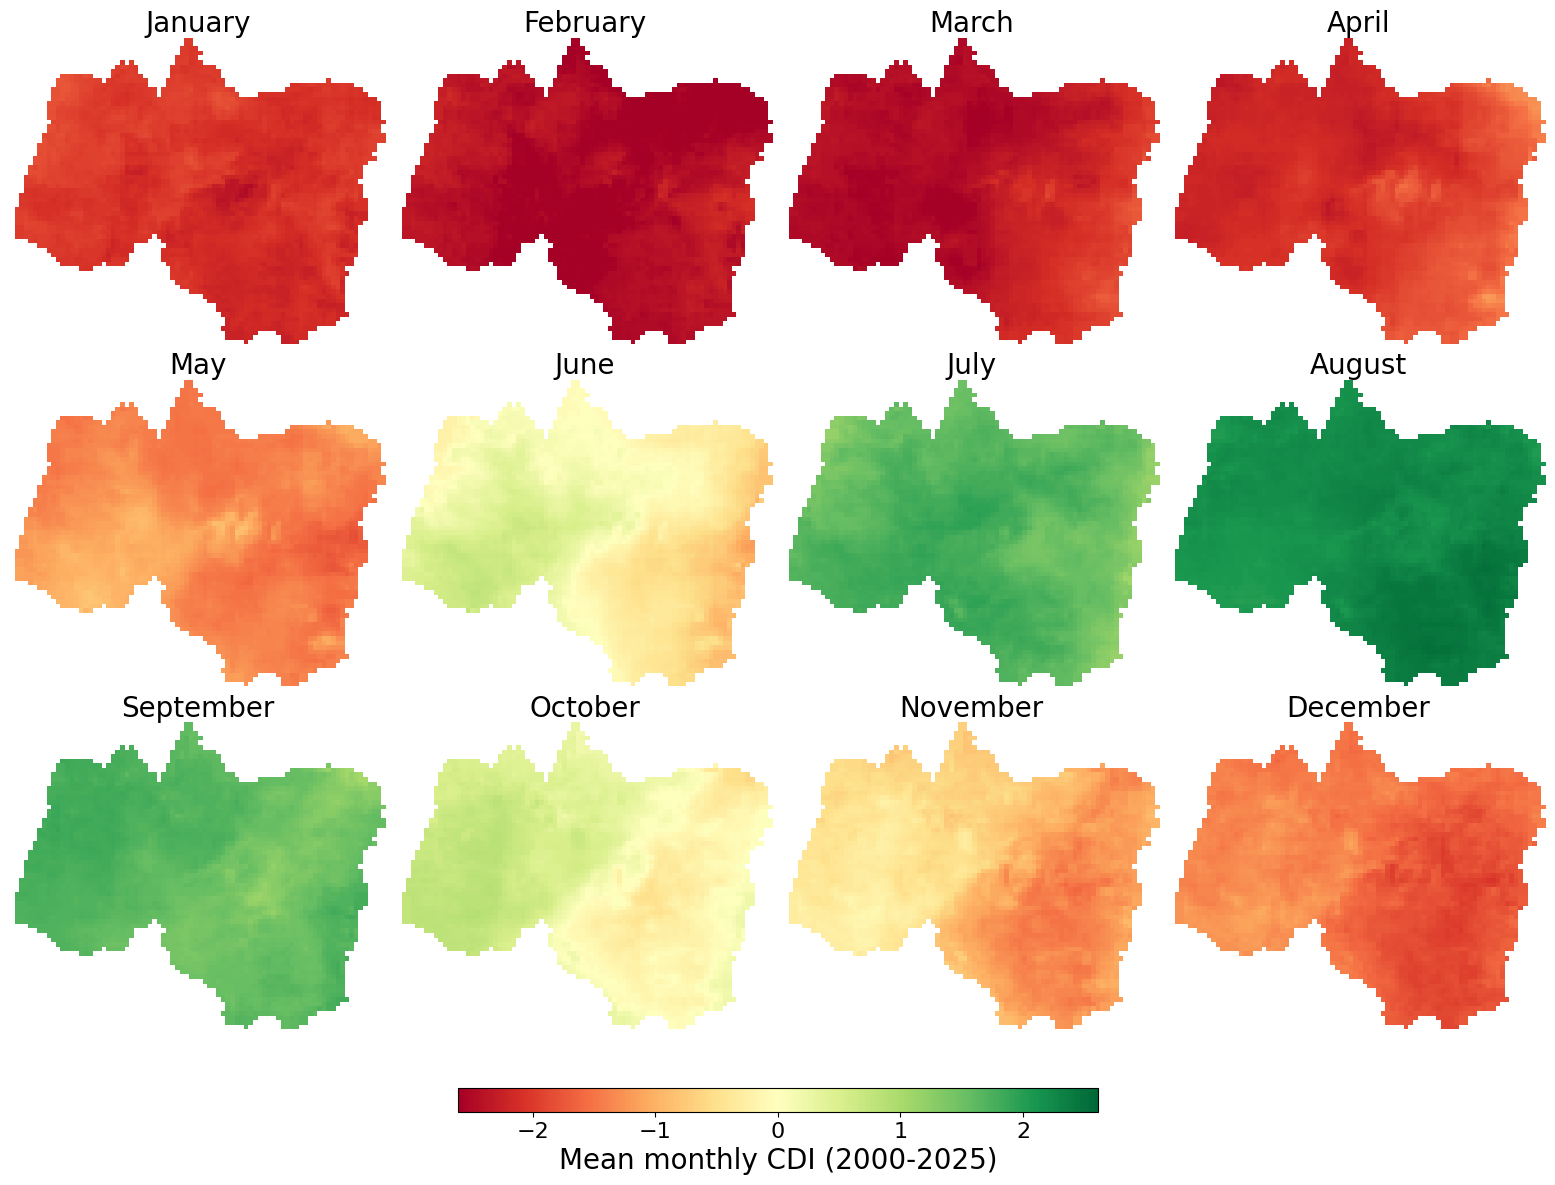


Saved figure : C:\Users\gerii\Documents\projects\tekeze\indices\CDI_CLIMATOLOGY\CDI_monthly_mean_2000_2025.png
Saved table  : C:\Users\gerii\Documents\projects\tekeze\indices\CDI_CLIMATOLOGY\CDI_range_comparison.csv
Saved rasters: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_CLIMATOLOGY

DONE


In [7]:
# =============================================================================
# MONTHLY CDI CLIMATOLOGY 2000-2025 (26-YEAR MEAN OF EACH CALENDAR MONTH)
# =============================================================================
#
# For each calendar month (Jan-Dec), averages the monthly CDI over all years
# 2000-2025 and maps the 12 results as continuous values (no drought classes).
#
# ALSO PRODUCES A RANGE-COMPARISON TABLE to document how averaging narrows
# the CDI range at each level:
#   Monthly CDI              : all pixels, all 312 months
#   Annual mean CDI          : mean of the 12 months of each year (26 values)
#   26-yr mean of each month : 12 climatology maps
#
# INPUT:
#   indices\CDI_OUTPUT_CLIPPED\CDI_yyyy_mm.tif   (monthly CDI)
#   Files that do not match this name pattern are skipped and listed.
#
# OUTPUT:
#   indices\CDI_CLIMATOLOGY\CDI_clim_mm.tif                (12 rasters)
#   indices\CDI_CLIMATOLOGY\CDI_monthly_mean_2000_2025.png (3 x 4 figure)
#   indices\CDI_CLIMATOLOGY\CDI_range_comparison.csv       (range table)
#
# COLOUR SCALE:
#   One shared diverging scale for all 12 panels, symmetric around 0.
#   By default the limits come from the 2nd and 98th percentile of the
#   climatology values; set FIXED_LIMIT to force them (e.g. 1.14).
#   Do NOT compare colours with the annual or monthly figures: each figure has
#   its own scale and its own colour bar.
# =============================================================================

import os
import re
import csv
import glob
import warnings
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# =============================================================================
# SETTINGS
# =============================================================================

START_YEAR  = 2000
END_YEAR    = 2025

CMAP_NAME   = "RdYlGn"      # red = dry, green = wet
FIXED_LIMIT = None          # None = automatic symmetric limits; or e.g. 1.14

MONTH_NAMES = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

FS_TITLE = 20
FS_CBAR  = 20

# =============================================================================
# PATHS
# =============================================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\indices"
folder   = os.path.join(BASE_DIR, "CDI_OUTPUT_CLIPPED")
OUT_DIR  = os.path.join(BASE_DIR, "CDI_CLIMATOLOGY")
os.makedirs(OUT_DIR, exist_ok=True)

OUT_PNG = os.path.join(OUT_DIR, "CDI_monthly_mean_2000_2025.png")
OUT_CSV = os.path.join(OUT_DIR, "CDI_range_comparison.csv")

# =============================================================================
# FIND THE MONTHLY FILES
# =============================================================================

pattern = re.compile(r"^CDI_(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)
files = {}                      # (year, month) -> path
skipped = []

for f in sorted(glob.glob(os.path.join(folder, "CDI_*.tif"))):
    name = os.path.basename(f)
    mt = pattern.match(name)
    if mt is None:
        skipped.append(name)
        continue
    y, m = int(mt.group(1)), int(mt.group(2))
    if START_YEAR <= y <= END_YEAR and 1 <= m <= 12:
        files[(y, m)] = f

if skipped:
    print(f"Skipped {len(skipped)} files that do not match CDI_yyyy_mm.tif:")
    for s in skipped:
        print("   ", s)

years = list(range(START_YEAR, END_YEAR + 1))
print("=" * 60)
print(f"{len(files)} monthly files found (expected {len(years) * 12})")
print("=" * 60)
if not files:
    raise SystemExit("No monthly CDI files found. Check the folder path and names.")

# =============================================================================
# READ ALL MONTHLY RASTERS
# =============================================================================

arrays = {}
profile = None

for (y, m), f in files.items():
    with rasterio.open(f) as src:
        a = src.read(1).astype("float32")
        if src.nodata is not None and not np.isnan(src.nodata):
            a[a == src.nodata] = np.nan
        arrays[(y, m)] = a
        if profile is None:
            profile = src.profile.copy()
            extent = (src.bounds.left, src.bounds.right,
                      src.bounds.bottom, src.bounds.top)

# =============================================================================
# 26-YEAR MEAN OF EACH CALENDAR MONTH
# =============================================================================

clim = {}
for m in range(1, 13):
    stack = [arrays[(y, m)] for y in years if (y, m) in arrays]
    if len(stack) == 0:
        continue
    if len(stack) < len(years):
        print(f"  WARNING: month {m:02d} has only {len(stack)} of {len(years)} years")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        clim[m] = np.nanmean(stack, axis=0).astype("float32")

# save the 12 climatology rasters
out_profile = profile.copy()
out_profile.update(dtype="float32", count=1, nodata=np.nan, compress="lzw")
for m, a in clim.items():
    with rasterio.open(os.path.join(OUT_DIR, f"CDI_clim_{m:02d}.tif"),
                       "w", **out_profile) as dst:
        dst.write(a, 1)

# =============================================================================
# RANGE COMPARISON: MONTHLY vs ANNUAL vs 26-YEAR MONTHLY MEAN
# =============================================================================

def describe(label, arr_list):
    v = np.concatenate([a[~np.isnan(a)].ravel() for a in arr_list])
    return [label, len(v), round(float(v.min()), 3), round(float(v.max()), 3),
            round(float(np.percentile(v, 2)), 3), round(float(np.percentile(v, 98)), 3),
            round(float(v.std()), 3)]

# annual mean per pixel, complete years only
annual = []
for y in years:
    if all((y, m) in arrays for m in range(1, 13)):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            annual.append(np.nanmean([arrays[(y, m)] for m in range(1, 13)], axis=0))

table = [
    describe("Monthly CDI (all months)", list(arrays.values())),
    describe("Annual mean CDI (12-month mean)", annual),
    describe("26-yr mean of each calendar month", list(clim.values())),
]

header = ["level", "n_values", "min", "max", "p2", "p98", "std"]
with open(OUT_CSV, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(header)
    w.writerows(table)

print("\nRANGE COMPARISON (pixel values)")
print(f"{'level':38s}{'min':>8s}{'max':>8s}{'p2':>8s}{'p98':>8s}{'std':>8s}")
for r in table:
    print(f"{r[0]:38s}{r[2]:8.2f}{r[3]:8.2f}{r[4]:8.2f}{r[5]:8.2f}{r[6]:8.2f}")

# =============================================================================
# SHARED COLOUR LIMITS (SYMMETRIC AROUND 0)
# =============================================================================

if FIXED_LIMIT is not None:
    lim = float(FIXED_LIMIT)
else:
    vals = np.concatenate([a[~np.isnan(a)] for a in clim.values()])
    lim = float(max(abs(np.percentile(vals, 2)), abs(np.percentile(vals, 98))))

norm = Normalize(vmin=-lim, vmax=lim)
print(f"\nColour scale: {-lim:.2f} to {lim:.2f}")

# =============================================================================
# FIGURE: 3 rows x 4 columns (Jan-Dec)
# =============================================================================

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for m in range(1, 13):
    ax = axes[m - 1]
    if m in clim:
        ax.imshow(clim[m], cmap=CMAP_NAME, norm=norm, extent=extent,
                  interpolation="nearest", aspect="equal")
    else:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", fontsize=14)
    ax.set_title(MONTH_NAMES[m - 1], fontsize=FS_TITLE, pad=4)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

sm = ScalarMappable(norm=norm, cmap=CMAP_NAME)
sm.set_array([])
cax = fig.add_axes([0.30, 0.055, 0.40, 0.02])
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.set_label("Mean monthly CDI (2000-2025)", fontsize=FS_CBAR)
cbar.ax.tick_params(labelsize=FS_CBAR - 4)

plt.subplots_adjust(left=0.02, right=0.98, top=0.95, bottom=0.12,
                    wspace=0.03, hspace=0.10)

plt.savefig(OUT_PNG, dpi=450, bbox_inches="tight")
plt.show()

print("\nSaved figure :", OUT_PNG)
print("Saved table  :", OUT_CSV)
print("Saved rasters:", OUT_DIR)
print("\nDONE")

### drought averaged months AGRICULTURAL CDI over 26 years,2000-2025

MODE = climatology: 12 layers read
Minimum CDI: min = -2.951, mean = -2.510, max = -2.082
Pixels whose driest month is: {'Jan': 9, 'Feb': 2300, 'Mar': 1111, 'Apr': 0, 'May': 0, 'Jun': 0, 'Jul': 0, 'Aug': 0, 'Sep': 0, 'Oct': 0, 'Nov': 0, 'Dec': 0}


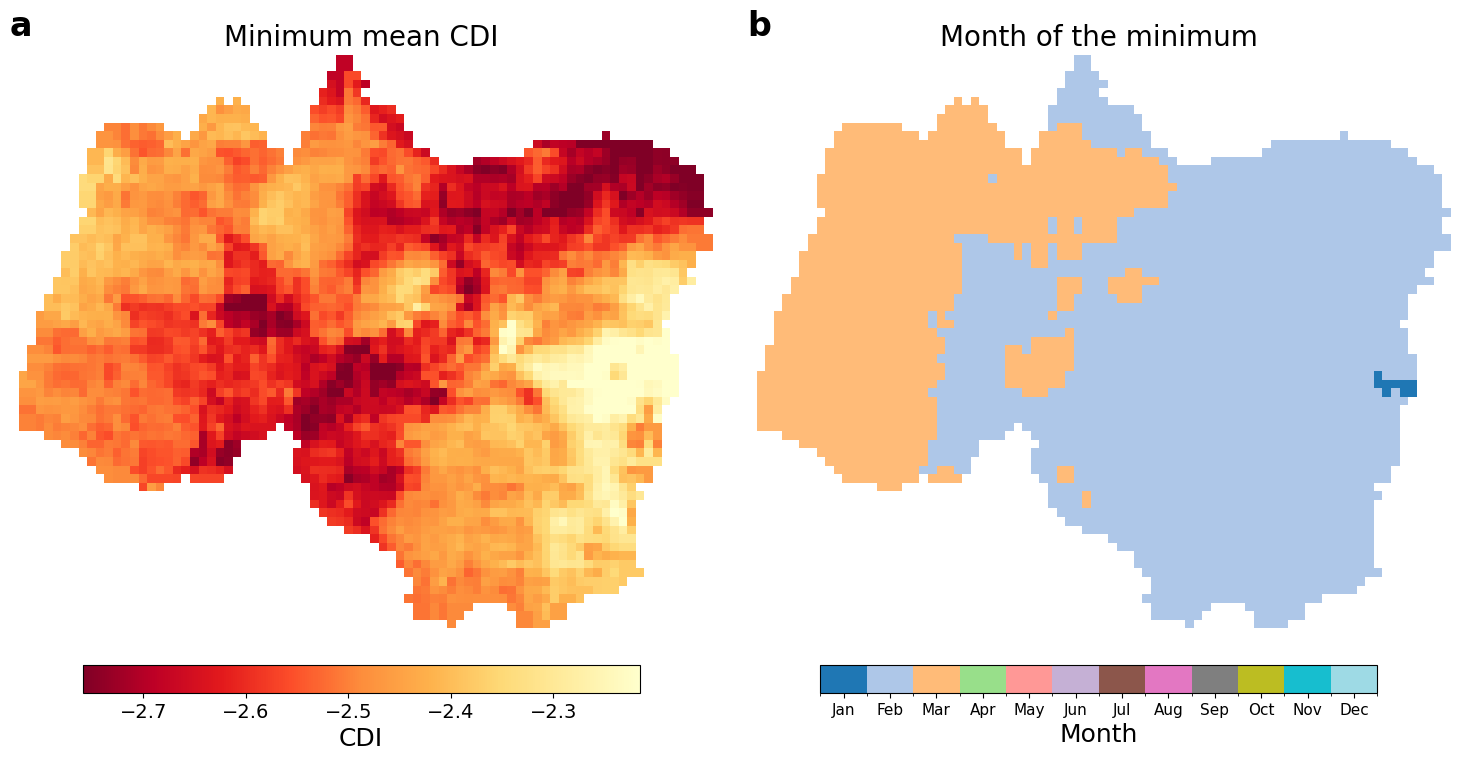


Saved: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_CLIMATOLOGY\CDI_min_value.tif
Saved: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_CLIMATOLOGY\CDI_min_month.tif
Saved: C:\Users\gerii\Documents\projects\tekeze\indices\CDI_CLIMATOLOGY\CDI_min_map_climatology.png
DONE


In [8]:
# =============================================================================
# MINIMUM OF THE 26-YEAR MONTHLY MEAN CDI PER PIXEL (DRIEST AVERAGE MONTH)
# =============================================================================
#
# For each pixel, takes the lowest of the 12 climatological monthly mean CDI
# values (2000-2025) and maps it as a continuous value (no drought classes).
# Also maps the calendar month in which that minimum occurs.
#
# MODE:
#   "climatology" : minimum over the 12 monthly means (mean of each calendar
#                   month over 2000-2025)            -> typical driest month
#   "all_months"  : minimum over all 312 monthly CDI values
#                   -> most extreme single month ever recorded at the pixel
#
# INPUT:
#   indices\CDI_CLIMATOLOGY\CDI_clim_mm.tif   (used if MODE = "climatology";
#                                              created by the climatology script)
#   indices\CDI_OUTPUT_CLIPPED\CDI_yyyy_mm.tif (used if MODE = "all_months")
#
# OUTPUT:
#   indices\CDI_CLIMATOLOGY\CDI_min_value.tif   (minimum CDI per pixel)
#   indices\CDI_CLIMATOLOGY\CDI_min_month.tif   (month of the minimum, 1-12)
#   indices\CDI_CLIMATOLOGY\CDI_min_map_<MODE>.png
# =============================================================================

import os
import re
import glob
import warnings
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, BoundaryNorm

# =============================================================================
# SETTINGS
# =============================================================================

MODE        = "climatology"      # "climatology" or "all_months"
START_YEAR  = 2000
END_YEAR    = 2025
CMAP_NAME   = "YlOrRd_r"         # dark red = lowest (driest) CDI
FIXED_RANGE = None               # None = automatic, or e.g. (-1.5, 0)

MONTH_ABBR = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

FS_TITLE = 20
FS_CBAR  = 18

# =============================================================================
# PATHS
# =============================================================================

BASE_DIR  = r"C:\Users\gerii\Documents\projects\tekeze\indices"
CLIM_DIR  = os.path.join(BASE_DIR, "CDI_CLIMATOLOGY")
MONTH_DIR = os.path.join(BASE_DIR, "CDI_OUTPUT_CLIPPED")
os.makedirs(CLIM_DIR, exist_ok=True)

OUT_VAL = os.path.join(CLIM_DIR, "CDI_min_value.tif")
OUT_MON = os.path.join(CLIM_DIR, "CDI_min_month.tif")
OUT_PNG = os.path.join(CLIM_DIR, f"CDI_min_map_{MODE}.png")

# =============================================================================
# READ HELPER
# =============================================================================

def read_cdi(path):
    with rasterio.open(path) as src:
        a = src.read(1).astype("float32")
        if src.nodata is not None and not np.isnan(src.nodata):
            a[a == src.nodata] = np.nan
        return a, src.profile.copy(), src.bounds

# =============================================================================
# BUILD THE STACK (n, H, W) AND ITS MONTH LABELS
# =============================================================================

stack, month_of_layer = [], []
profile = bounds = None

if MODE == "climatology":
    for m in range(1, 13):
        p = os.path.join(CLIM_DIR, f"CDI_clim_{m:02d}.tif")
        if not os.path.exists(p):
            raise SystemExit(f"Missing {p}. Run the climatology script first, "
                             f"or set MODE = 'all_months'.")
        a, prof, b = read_cdi(p)
        stack.append(a); month_of_layer.append(m)
        profile, bounds = prof, b

elif MODE == "all_months":
    pattern = re.compile(r"^CDI_(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)
    for f in sorted(glob.glob(os.path.join(MONTH_DIR, "CDI_*.tif"))):
        mt = pattern.match(os.path.basename(f))
        if mt is None:
            continue
        y, m = int(mt.group(1)), int(mt.group(2))
        if START_YEAR <= y <= END_YEAR and 1 <= m <= 12:
            a, prof, b = read_cdi(f)
            stack.append(a); month_of_layer.append(m)
            profile, bounds = prof, b
else:
    raise SystemExit("MODE must be 'climatology' or 'all_months'.")

if not stack:
    raise SystemExit("No CDI rasters found. Check the folder paths.")

stack = np.stack(stack)
month_of_layer = np.array(month_of_layer)
print(f"MODE = {MODE}: {stack.shape[0]} layers read")

# =============================================================================
# PER-PIXEL MINIMUM AND ITS MONTH
# =============================================================================

all_nan = np.all(np.isnan(stack), axis=0)
filled  = np.where(np.isnan(stack), np.inf, stack)

idx     = np.argmin(filled, axis=0)
min_val = np.take_along_axis(stack, idx[None], axis=0)[0].astype("float32")
min_mon = month_of_layer[idx].astype("float32")

min_val[all_nan] = np.nan
min_mon[all_nan] = np.nan

print(f"Minimum CDI: min = {np.nanmin(min_val):.3f}, "
      f"mean = {np.nanmean(min_val):.3f}, max = {np.nanmax(min_val):.3f}")

counts = {MONTH_ABBR[m - 1]: int(np.sum(min_mon == m)) for m in range(1, 13)}
print("Pixels whose driest month is:", counts)

# =============================================================================
# SAVE RASTERS
# =============================================================================

out_profile = profile.copy()
out_profile.update(dtype="float32", count=1, nodata=np.nan, compress="lzw")

with rasterio.open(OUT_VAL, "w", **out_profile) as dst:
    dst.write(min_val, 1)
with rasterio.open(OUT_MON, "w", **out_profile) as dst:
    dst.write(min_mon, 1)

# =============================================================================
# FIGURE: (a) minimum CDI, (b) month of the minimum
# =============================================================================

extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)

if FIXED_RANGE is not None:
    vmin, vmax = FIXED_RANGE
else:
    vmin = float(np.nanpercentile(min_val, 2))
    vmax = float(np.nanpercentile(min_val, 98))
norm_val = Normalize(vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# panel a: minimum value
ax = axes[0]
ax.imshow(min_val, cmap=CMAP_NAME, norm=norm_val, extent=extent,
          interpolation="nearest", aspect="equal")
ax.set_title("Minimum mean CDI", fontsize=FS_TITLE, pad=6)
ax.text(0.0, 1.02, "a", transform=ax.transAxes, fontsize=FS_TITLE + 4,
        fontweight="bold", va="bottom", ha="left")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)

sm = ScalarMappable(norm=norm_val, cmap=CMAP_NAME); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.04, pad=0.04)
cb.set_label("CDI", fontsize=FS_CBAR)
cb.ax.tick_params(labelsize=FS_CBAR - 4)

# panel b: month of the minimum
ax = axes[1]
cmap_m = plt.get_cmap("tab20", 12)
norm_m = BoundaryNorm(np.arange(0.5, 13.5, 1), 12)
ax.imshow(min_mon, cmap=cmap_m, norm=norm_m, extent=extent,
          interpolation="nearest", aspect="equal")
ax.set_title("Month of the minimum", fontsize=FS_TITLE, pad=6)
ax.text(0.0, 1.02, "b", transform=ax.transAxes, fontsize=FS_TITLE + 4,
        fontweight="bold", va="bottom", ha="left")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)

sm2 = ScalarMappable(norm=norm_m, cmap=cmap_m); sm2.set_array([])
cb2 = fig.colorbar(sm2, ax=ax, orientation="horizontal", fraction=0.04, pad=0.04,
                   ticks=np.arange(1, 13))
cb2.ax.set_xticklabels(MONTH_ABBR)
cb2.set_label("Month", fontsize=FS_CBAR)
cb2.ax.tick_params(labelsize=FS_CBAR - 7)

plt.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.05, wspace=0.05)
plt.savefig(OUT_PNG, dpi=450, bbox_inches="tight")
plt.show()

print("\nSaved:", OUT_VAL)
print("Saved:", OUT_MON)
print("Saved:", OUT_PNG)
print("DONE")